# Figure4 Phase Space

Reproduces panels used in the main manuscript. Generated files are written to `logs/scripts/figure4_phase_space/`.


In [1]:
import os
import sys
import pathlib

if (ROOT := pathlib.Path(os.getcwd())).name == "scripts":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.append(str(ROOT))
print(ROOT)

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe


In [2]:
import re
import sys
import json
import yaml
import shlex
import random
import dotenv
import signal
import logging
import datetime
import nd2py as nd
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
from socket import gethostname
from argparse import Namespace
from argparse import ArgumentParser
from nd2py.utils import init_logger
from setproctitle import setproctitle
from src.utils import add_negation_flags, tag2ansi, log_exception
from src.core import Triplet, Individual
from src.assistant import Assistant
from src.ai_scientist import AIScientist
from src.ai_scientist_parallel import AIScientistParallel
from src.utils import wrap_ansi

import warnings
# warnings.simplefilter('error', RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="nd2py")

dotenv.load_dotenv()
_logger = logging.getLogger('src')

args = Namespace(**json.load(open('data/cache/default_args.json', 'r')))
args.save_dir = './logs/scripts'
args.exp_name = 'figure4_phase_space'
args.train_period = ['all', 'all']
args.test_period = ['all', 'all']
args.a_skill_after_2004 = 0.0

## Build Save Path
if args.exp_name is None:
    now = datetime.now()
    date = now.strftime("%Y%m%d")
    curr = now.strftime("%H%M%S")
    host = gethostname()
    exp_name = f'{date}_{args.name}_{curr}_{host}'
    exp_name = re.compile(r'[ <>:"/\\|?*\x00-\x1f]').sub('_', exp_name.strip())
    exp_name = exp_name or 'unnamed'
    exp_name = exp_name[:255] # Max filename length on most filesystems
    args.exp_name = exp_name
save_path = Path(args.save_dir) / args.exp_name
if not save_path.exists():
    save_path.mkdir(parents=True, exist_ok=True)
else:
    _logger.warning(f"Save path {save_path} already exists.")
args.save_path = str(save_path)

## Set Random State
if args.random_state is None:
    args.random_state = random.randint(0, 2**31 - 1)
## Set Command
args.command = ' '.join(map(shlex.quote, [sys.executable, *sys.argv]))

## Init Logger
init_logger(
    "src", 
    exp_name=args.exp_name, 
    log_file=save_path / "info.log", 
    info_level='debug' if args.debug else 'info',
    show_lineno_for_all_levels=args.debug,
)
nd2py_logger = logging.getLogger("nd2py")
nd2py_logger.setLevel(_logger.level)
nd2py_logger.handlers = _logger.handlers.copy()

## Save Args
args_path = save_path / "args.json"
if args_path.exists():
    i = 1
    while args_path.with_suffix(f".json.{i}").exists(): i += 1
    args_path.rename(args_path.with_suffix(f".json.{i}"))
    _logger.warning(f"args.json already exists, backup to args.json.{i}")
_logger.note(f"Args: {args}")
with open(args_path, "w") as f:
    json.dump(vars(args), f, indent=4, ensure_ascii=False)

# Start the main process
setproctitle(f"{args.exp_name}@ZihanYu")

## Load Assistant
assistant = Assistant(args)
## Load Data
# 加载变量
variables = assistant.load_variables()
# 加载数据
df_all = assistant.load_data(normalize_co2=False)
# 划分数据
if True:
    train_start, train_end = args.train_period
    test_start, test_end = args.test_period
    train_start = pd.Period(train_start, freq='M') if train_start != 'all' else df_all.index[0]
    train_end = pd.Period(train_end, freq='M') if train_end != 'all' else df_all.index[-1]
    test_start = pd.Period(test_start, freq='M') if test_start != 'all' else df_all.index[0]
    test_end = pd.Period(test_end, freq='M') if test_end != 'all' else df_all.index[-1]
    df_train = df_all.loc[train_start:train_end]
    df_test = df_all.loc[test_start:test_end]
elif False:
    df_train = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
    df_test = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
else:
    df_train = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=1999, month=12, freq='M')]
    df_test = df_all.loc[pd.Period(year=2000, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
# 准备拓扑
edge_list, num_nodes = assistant.load_topology()
# 打印日志
_logger.info(
    f"Data loaded: {len(df_all)} samples, "
    f"where {len(df_train)}({len(df_train)/len(df_all):.2%}) "
    f"from {df_train.index[0]} to {df_train.index[-1]} for training, "
    f"and {len(df_test)}({len(df_test)/len(df_all):.2%}) "
    f"from {df_test.index[0]} to {df_test.index[-1]} for testing."
)
_logger.info(
    f"Variables: " + ", ".join(f'{var_name}({len(sub_df)})' for var_name, sub_df in df_all.T.groupby(level=0)) + "."
)
## Load Seed Individuals
seed_individuals = assistant.load_seed_individuals()

## Initialize Runner
Runner = AIScientistParallel if args.parallel else AIScientist
kwargs = dict(
    args=args,
    assistant=assistant,
    variables=variables,
    binary=[
        getattr(nd, name) for name in args.binary
        # nd.Add, nd.Sub, nd.Mul, nd.Div
    ],
    unary=[
        getattr(nd, name) for name in args.unary
        # nd.Sin, nd.Cos,
        # nd.Exp, nd.LogAbs,
        # nd.Sigmoid, nd.Tanh,
        # nd.Pow2, nd.Pow3, nd.SqrtAbs,
        # nd.Aggr, nd.Readout, nd.Sour, nd.Targ,
    ],
    edge_list=edge_list,
    num_nodes=num_nodes,
    seed_individuals=seed_individuals,
)
_logger.note(f"Initializing Runner with args: {kwargs}")
est = Runner(**kwargs)
# Set Clip Bounds
est.evaluator.simulator.set_clip_bounds(df_all, clip_factor=args.clip_factor)

Save path logs/scripts/figure4_phase_space already exists.


[figure4_phase_space|src|W|Oct15 11:08:43|0:00:00.001487] (../../../../../../tmp/ipykernel_2674606/3119046923.py:84) args.json already exists, backup to args.json.3


[figure4_phase_space|src|N|Oct15 11:08:43|0:00:00.002879] Args: Namespace(name='Reduce_320_230_368', setting='only_co2', exp_name='figure4_phase_space', llm_model=None, llm_provider=None, seed_individuals=['co2_320_230_368'], load_seed_individuals=[], use_seed_individuals_only=True, num_workers=24, parallel=True, timeout=240, population_size=200, n_iter=300, programs_per_prompt=2, generate_per_prompt=8, expire_iter=1, keep_best=False, random_state=1581316702, score_func='tanh', a_rmse=0.0, a_trajrmse=0.0, a_skill_cv_sum=0.0, a_skill_cv_sum_inner=0.0, a_skill_cv_mean=0.0, a_ENSO_skill_cv=1.0, a_Total_skill_cv=10.0, a_skill_sum_inner=0.0, a_skill_sum=0.0, a_skill_mean=0.0, a_ENSO_skill=0.0, a_IOB_skill=0.0, a_SASD_skill=0.0, a_Total_skill=0.0, a_skill_after_2004=0.0, a_length=1.0, a_params=1.0, a_std=0.3, a_skewness=0.3, a_spectrum=0.3, a_leadlag=0.0, a_forecast=0.0, a_contain_co2=0.0, save_checkpoint_per_iter=1, max_params=5, save_dir='./logs/scripts', debug=False, log_per_iter=1, log_p

[figure4_phase_space|data_loader|I|Oct15 11:08:43|0:00:00.055905] Normalizing AOT data by min-max scaling (min=-0.018186562, max=0.2945641)


[figure4_phase_space|data_loader|I|Oct15 11:08:43|0:00:00.062438] Normalizing TSI data by min-max scaling (min=1360.7906, max=1363.2379)


...

[figure4_phase_space|src|I|Oct15 11:08:43|0:00:00.098760] Variables: ATL3(9), ENSO(9), IOB(9), IOD(9), NPMM(9), SASD(9), SIOD(9), SPMM(9), TNA(9), h(9), t(1), u_aot(1), u_co2(1), u_temp(1), u_tsi(1), x(9).


[figure4_phase_space|src|N|Oct15 11:08:43|0:00:00.120254] Initializing Runner with args: {'args': Namespace(name='Reduce_320_230_368', setting='only_co2', exp_name='figure4_phase_space', llm_model=None, llm_provider=None, seed_individuals=['co2_320_230_368'], load_seed_individuals=[], use_seed_individuals_only=True, num_workers=24, parallel=True, timeout=240, population_size=200, n_iter=300, programs_per_prompt=2, generate_per_prompt=8, expire_iter=1, keep_best=False, random_state=1581316702, score_func='tanh', a_rmse=0.0, a_trajrmse=0.0, a_skill_cv_sum=0.0, a_skill_cv_sum_inner=0.0, a_skill_cv_mean=0.0, a_ENSO_skill_cv=1.0, a_Total_skill_cv=10.0, a_skill_sum_inner=0.0, a_skill_sum=0.0, a_skill_mean=0.0, a_ENSO_skill=0.0, a_IOB_skill=0.0, a_SASD_skill=0.0, a_Total_skill=0.0, a_skill_after_2004=0.0, a_length=1.0, a_params=1.0, a_std=0.3, a_skewness=0.3, a_spectrum=0.3, a_leadlag=0.0, a_forecast=0.0, a_contain_co2=0.0, save_checkpoint_per_iter=1, max_params=5, save_dir='./logs/scripts', 

[figure4_phase_space|llm_api|W|Oct15 11:08:43|0:00:00.122330] (src/api/llm_api.py:47) No llm_provider or llm_model specified, returning base LLMAPI.


[figure4_phase_space|llm_provider|I|Oct15 11:08:43|0:00:00.123455] LLM Provider initialized with model: LLMAPI(None)


[figure4_phase_space|ai_scientist_parallel|I|Oct15 11:08:43|0:00:00.125432] Using 24 workers for parallel fitness evaluation.


In [3]:
args.a_rmse = 0.0
args.a_trajrmse = 0.0
args.a_skill_cv_sum = 0.0
args.a_skill_cv_sum_inner = 0.0
args.a_skill_cv_mean = 0.0
args.a_ENSO_skill_cv = 1.0
args.a_ATL3_skill_cv = 1.0
args.a_SASD_skill_cv = 1.0
args.a_Total_skill_cv = 10.0
args.a_skill_sum_inner = 0.0
args.a_skill_sum = 0.0
args.a_skill_mean = 0.0
args.a_ENSO_skill = 0.0
args.a_IOB_skill = 0.0
args.a_SASD_skill = 0.0
args.a_Total_skill = 0.0
args.a_skill_after_2004 = 1.0
args.a_length = 1.0
args.a_params = 0.0
args.a_std = 0.25
args.a_skewness = 0.25
args.a_spectrum = 0.25
args.a_leadlag = 0.25
args.a_forecast = 0.0
args.a_contain_co2 = 0.0
args.max_month = 40
args.a_correlation_auc_sum = 0.0
args.a_correlation_auc_cv_sum = 0.0

args.damp = 1e-1
args.atol = 1e-6
args.btol = 1e-6
args.iter_lim = None

In [4]:
baseline_indiv = assistant.load_baseline_indiv()

def evaluate3(indiv, df_test, df_train=None):
    if df_train is None:
        df_train = df_test

    # Set Ground Truth Results
    _logger.info(f"Calculating ground truth result on test data...")
    est.evaluator.set_ground_truth_result(df_test)
    # Set XRO Baseline Results
    _logger.info(f"Evaluating XRO on test data as baseline...")
    baseline_dynamics = assistant.triplet_to_dynamics(baseline_indiv.triplet)
    baseline_indiv.dynamics, mse = est.evaluator.fitter.fit_parameters(baseline_dynamics, df_train, nonlinear=True)
    est.evaluator.set_baseline_result(baseline_indiv.dynamics, df_test, use_tqdm=False)
    baseline_indiv.fitness, baseline_indiv.detail = est.evaluator.get_fitness(est.evaluator.baseline_result)
    baseline_log = est.get_log_for_indiv(baseline_indiv)
    if False:
        _logger.info(tag2ansi(f"[green]Evaluate XRO on Test Data from {df_test.index[0]} to {df_test.index[-1]} (parameters are fitted on Train Data from {df_train.index[0]} to {df_train.index[-1]})[reset]"))
        _logger.info(tag2ansi("\n".join(f"[#66CCFF]{k.strip('\n')}[reset]={wrap_ansi(tag2ansi(v), 150).strip('\n')}" for k, v in baseline_log.items())))

    est.evaluator.set_fitness(indiv, df_test, df_fit=df_train, use_tqdm=False)
    log = est.get_log_for_indiv(indiv)
    _logger.info(tag2ansi(f"[green]Evaluate on Test Data from {df_test.index[0]} to {df_test.index[-1]} (parameters are fitted on Train Data from {df_train.index[0]} to {df_train.index[-1]})[reset]"))
    _logger.info(tag2ansi("\n".join(f"[#66CCFF]{k.strip('\n')}[reset]={wrap_ansi(tag2ansi(v), 150).strip('\n')}" for k, v in log.items())))

In [5]:
# df_all = assistant.load_data(normalize_co2=True)
df_all = assistant.load_data(normalize_co2=False)

triplet = assistant.program_to_triplet("""
def get_equations(t, x, h, u_co2, mode, nl_params):
    coeff = 1 + cos(t) + sin(t) + sin(0.50 * t) + sin(2 * t)
    dx_dt = Variable('damping_flag') * x + \
            Variable('recharging_flag') * mode['ENSO'] * h + \
            Variable('co2_flag') * log(u_co2) + \
            aggr( 
                Variable('slow_flag') * sour(x) + \
                Variable('fast_flag') * tanh(0.70 * sour(h)) * (1.00 + 1.20 * targ(x) + 1.10 * readout(x))
            )
    dh_dt = Variable('damping_flag') * h + \
            Variable('Tbar_flag') * readout(x) ** 2 + \
            aggr(
                Variable('slow_flag') * sour(x) + \
                Variable('fast_flag') * tanh(2.00 * sour(h)) * (0.65 + 0.60 * targ(h) + 0.10 * readout(x))
            )
    return coeff, dx_dt, dh_dt
""")
indiv = Individual(
    uuid=None,
    n_iter=None,
    source=None,
    parents=[],
    program=assistant.triplet_to_program(triplet),
    triplet=triplet,
    dynamics=assistant.triplet_to_dynamics(triplet),
)

args.a_skill_after_2004 = 0.0
args.use_nfold_cv = True
args.use_l3yo_cv = False
df_all[('damping_flag', 'value')] = 1
df_all[('recharging_flag', 'value')] = 1
df_all[('co2_flag', 'value')] = 1
df_all[('slow_flag', 'value')] = 1
df_all[('fast_flag', 'value')] = 1
df_all[('Tbar_flag', 'value')] = 1
evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])

[figure4_phase_space|data_loader|I|Oct15 11:08:43|0:00:00.220027] Normalizing AOT data by min-max scaling (min=-0.018186562, max=0.2945641)


[figure4_phase_space|data_loader|I|Oct15 11:08:43|0:00:00.226285] Normalizing TSI data by min-max scaling (min=1360.7906, max=1363.2379)


/tmp/ipykernel_2674606/951016205.py:35: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_all[('damping_flag', 'value')] = 1
/tmp/ipykernel_2674606/951016205.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_all[('recharging_flag', 'value')] = 1
/tmp/ipykernel_2674606/951016205.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented fra

[figure4_phase_space|src|I|Oct15 11:08:47|0:00:04.445008] Evaluating XRO on test data as baseline...


[figure4_phase_space|fitness_evaluator|I|Oct15 11:08:56|0:00:13.167203] Split data into 5 folds for N-Fold CV: DatetimeIndex(['1979-01-01 00:00:00', '1988-03-08 04:48:00',
                       '1997-05-14 09:36:00', '2006-07-20 14:24:00',
                       '2015-09-25 19:12:00', '2024-12-01 00:00:00'],
                      dtype='datetime64[ns]', freq=None)


...

[figure4_phase_space|fitness_evaluator|I|Oct15 11:08:56|0:00:13.171178] Fold 2: 1997-06 to 2006-07


[figure4_phase_space|fitness_evaluator|I|Oct15 11:08:56|0:00:13.172054] Fold 3: 2006-08 to 2015-09


[figure4_phase_space|fitness_evaluator|I|Oct15 11:08:56|0:00:13.172763] Fold 4: 2015-10 to 2024-12


[figure4_phase_space|src|I|Oct15 11:09:25|0:00:42.471205] Evaluate on Test Data from 1979-01 to 2024-12 (parameters are fitted on Train Data from 1979-01 to 2024-12)


[figure4_phase_space|src|I|Oct15 11:09:25|0:00:42.473481] Info=None from None() at Iter None
        Fitness=4.331163
        Skills=x_ENSO=32 month; x_NPMM=17 month; x_SPMM=5 month; x_IOB=29 month; x_IOD=13 month; x_SIOD=19 month; x_TNA=10 month; x_ATL3=5 month; x_SASD=5 month; h_E
        NSO=24 month; h_NPMM=23 month; h_SPMM=20 month; h_IOB=33 month; h_IOD=24 month; h_SIOD=29 month; h_TNA=15 month; h_ATL3=6 month; h_SASD=15 month;Total
         SST=135 month;Total Z20=189 month;Total=324 month
        Skills%=x_ENSO=+68.42%;x_NPMM=-5.56%;x_SPMM=+0.00%;x_IOB=+26.09%;x_IOD=+116.67%;x_SIOD=+18.75%;x_TNA=+0.00%;x_ATL3=+25.00%;x_SASD=-28.57%;h_ENSO=+41.18%;h_NPM
        M=+21.05%;h_SPMM=+25.00%;h_IOB=+106.25%;h_IOD=+118.18%;h_SIOD=+70.59%;h_TNA=+25.00%;h_ATL3=+50.00%;h_SASD=-6.25%;SST=+25.00%;Z20=+47.66%;Total=+37.29%
        Skills (CV)=x_ENSO=27 month; x_NPMM=10 month; x_SPMM=3 month; x_IOB=27 month; x_IOD=8 month; x_SIOD=16 month; x_TNA=6 month; x_ATL3=3 month; x_SASD=3 month; h_ENS
 

In [6]:
args.use_nfold_cv = False
args.use_l3yo_cv = False
args.n_member = 10
args.max_month = 45*12
args.generation_max_month = 45*12
# evaluation = est.evaluator.get_evaluation(indiv.dynamics, df_all.loc[f'1979-{i:02d}':'2024-12'], use_tqdm=False)
f = indiv.dynamics

In [7]:
# 初始状态：1979-01
# 外部强迫：1979-01 到 2024-12 的真实 CO2 数据
# 公式参数：在 1979-2024 上矫正得到的参数
df = df_all.loc[f'1979-01':'2024-12'].copy()
dt = df['t'].values[1, 0] - df['t'].values[0, 0]
PREDICTION = est.evaluator.simulator.get_simulation_with_forcing(
    f, df[['x', 'h', 't']].iloc[:1], dt, df.drop(columns=['x', 'h', 't']), max_month=45*12, tqdm_desc='PREDICTION'
)

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/tmp/ipykernel_2674606/2278708110.py:7: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  f, df[['x', 'h', 't']].iloc[:1], dt, df.drop(columns=['x', 'h', 't']), max_month=45*12, tqdm_desc='PREDICTION'


/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

...

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

In [8]:
# 初始状态：1979-01
# 外部强迫：固定在 1979-01 的 fixed CO2 数据
# 公式参数：在 1979-2024 上矫正得到的参数
df = df_all.loc[f'1979-01':'2024-12'].copy()
df[('u_co2', 'value')] = df[('u_co2', 'value')].iloc[0] # 固定CO2为初始值
dt = df['t'].values[1, 0] - df['t'].values[0, 0]
PREDICTION_wo_co2 = est.evaluator.simulator.get_simulation_with_forcing(
    f, df[['x', 'h', 't']].iloc[:1], dt, df.drop(columns=['x', 'h', 't']), max_month=45*12, tqdm_desc='PREDICTION_wo_co2'
)

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/tmp/ipykernel_2674606/3407667397.py:8: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  f, df[['x', 'h', 't']].iloc[:1], dt, df.drop(columns=['x', 'h', 't']), max_month=45*12, tqdm_desc='PREDICTION_wo_co2'


/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

...

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.preprocessing import StandardScaler

stop = PREDICTION.index.get_level_values('time') + PREDICTION.index.get_level_values('lead')
df = PREDICTION.reset_index().assign(stop=stop).set_index('time').loc['1979-01'].iloc[200:]

X = df[['x', 'h']].values
co2 = df_all.loc[df['stop']][('u_co2', 'value')].values
time = df['stop'].values
time_steps = np.arange(X.shape[0])

scalar = StandardScaler()
X = scalar.fit_transform(X) # 标准化数据，确保 PCA 和 PLS 不受尺度影响

# 1. 优先提取最大方差
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X) # X 和 Y 轴搞定了！

# 2. 计算与前两个主成分绝对正交的“残差空间”
# inverse_transform 会把 2D 的圈重新映射回 18 维空间（这是仅由 PC1 和 PC2 构成的信息）
# 从原始 18 维数据中，减去被 PCA 拿走的部分，得到纯净的垂直/正交空间
X_residual = X - pca.inverse_transform(X_pca)

# 3. 在剩下的垂直空间里，寻找与 co2 最相关的 1 个维度
pls = PLSRegression(n_components=1)
X_pls, _ = pls.fit_transform(X_residual, co2)

df_raw = df.set_index('stop')[['x', 'h']]
df_plot = pd.DataFrame({
    'x': X_pca[:, 0],
    'y': X_pca[:, 1],
    'z': X_pls[:, 0],
    'time': time,
    'co2': co2,
})

def dynamical_map(df):
    df = df.copy()
    stop = df.index.get_level_values('time') + df.index.get_level_values('lead')
    df = df.reset_index().assign(stop=stop).set_index('time')

    X = df[['x', 'h']].values

    X = scalar.fit_transform(X)

    X_pca = pca.transform(X)

    X_residual = X - pca.inverse_transform(X_pca)

    X_pls = pls.transform(X_residual)

    return pd.DataFrame({
        'x': X_pca[:, 0],
        'y': X_pca[:, 1],
        'z': X_pls[:, 0],
        'time': df['stop'].values,
        'co2': df[('co2', 'value')].values if 'co2' in df else None,
    })

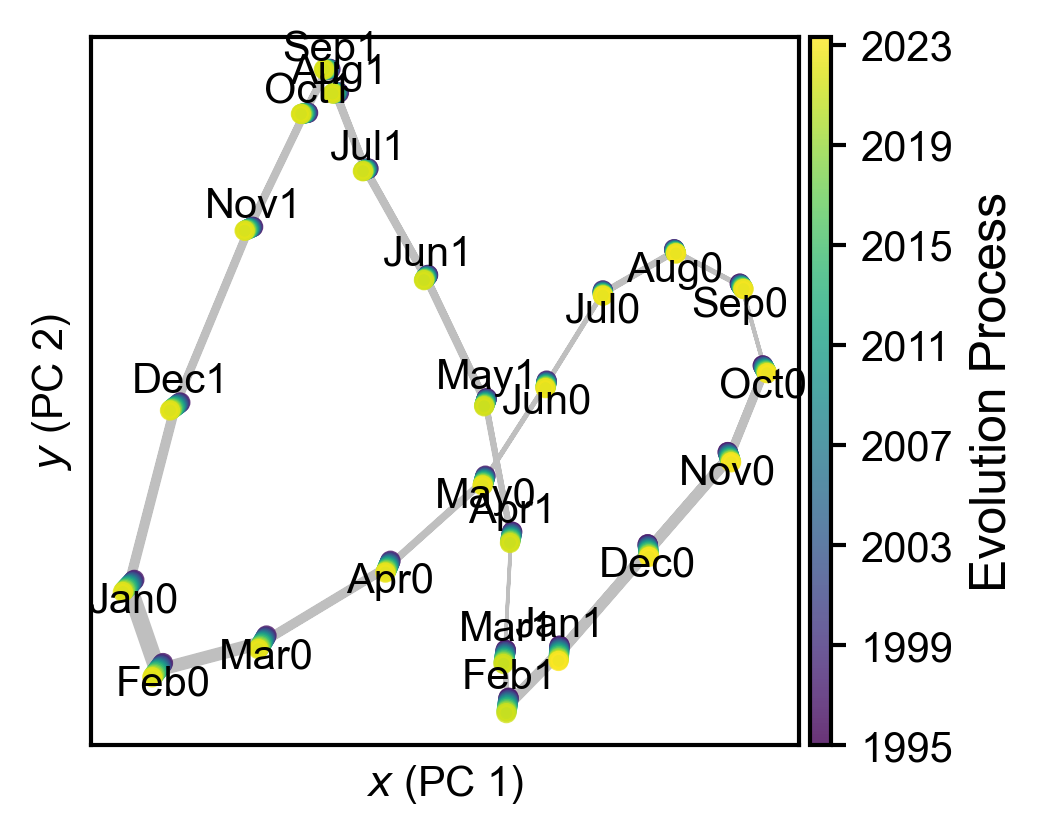

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
# from yumeow_plot import get_fig
from nd2py.utils.plot import get_fig
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

fi, fig, axes = get_fig(1, 1, AW=6, AH=6, dpi=300, lw=1, fontsize=14)
df_plot = dynamical_map(PREDICTION.loc[['1979-01']].iloc[200:])

if True:
    ax = axes[0]
    x, y, w, h = ax.get_position().bounds
    ax.plot(df_plot['x'], df_plot['y'], zorder=0, color='gray', linewidth=0.5, alpha=0.5) # 建议加上连线看清轨迹
    sc0 = ax.scatter(df_plot['x'], df_plot['y'], c=mdates.date2num(df_plot['time'].values), cmap='viridis', s=15, alpha=0.8)
    ax.set_xlabel('$x$ (PC 1)', fontsize=10)
    ax.set_ylabel('$y$ (PC 2)', fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

    curr = 0
    for i in range(24):
        month = df_plot.iloc[i]['time'].strftime('%b') 
        if month == 'Jan': curr = (curr + 1) % 2
        ax.annotate(
            # f"{month}$^{{{curr}}}$",
            f"{month}{curr}",
            (df_plot.iloc[i]['x'], df_plot.iloc[i]['y']),
            xytext=(0, 5 if curr else -5), # 将文字向右上方偏移 5 个像素，防止与点重叠
            textcoords='offset points',
            fontsize=10,
            color='black',
            ha='center',
            va='center',
            zorder=10 # 确保文字浮在散点之上
        )

    cax = fig.add_axes([x + w + 0.01, y, 0.02, h]) # 在主图右侧添加一个新的坐标轴用于颜色条
    cbar = fig.colorbar(sc0, cax=cax, label='Evolution Process')
    cbar.set_label('Evolution Process', fontsize=12)
    cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    cbar.ax.set_yticks(mdates.date2num(df_plot['time'].iloc[::48].values))  # 每隔 24 个月设置一个刻度

fig.savefig(Path(save_path) / 'Fig4e.png', dpi=300, bbox_inches='tight', transparent=True)
fig.savefig(Path(save_path) / 'Fig4e.svg', dpi=300, bbox_inches='tight', transparent=True)
fig.savefig(Path(save_path) / 'Fig4e.pdf', dpi=300, bbox_inches='tight', transparent=True)

In [11]:
import matplotlib.colors as mcolors
import seaborn as sns
from scipy.interpolate import splprep, splev
import pyvista as pv

# Panel g: use the effective PLS direction in the original 18-dimensional
# state space, as in 260414检查吸引子.ipynb.
feature_names = df_raw.columns.map(lambda x: rf'${"T" if x[0] == "x" else "h"}_{{{x[1]}}}$').to_list()
projection_matrix = np.eye(len(feature_names)) - pca.components_.T @ pca.components_
weight_z_effective = (projection_matrix @ pls.x_rotations_).ravel()
df_weights = pd.DataFrame({
    'name': feature_names,
    'x': pca.components_[0],
    'y': pca.components_[1],
    'z': weight_z_effective,
})
fig, axes = plt.subplots(1, 3, figsize=(7.2, 5.0), sharey=True, dpi=200)
norm = plt.Normalize(-0.5, 0.5)
cmap = mcolors.LinearSegmentedColormap.from_list('weights', ['#546de5', '#ffffff', '#c44569'])
for ax, target in zip(axes, ['x', 'y', 'z']):
    sns.barplot(y='name', x=target, data=df_weights, ax=ax, color='gray')
    for patch in ax.patches:
        patch.set_facecolor(cmap(norm(patch.get_width())))
    ax.set_title(f'Weights of {target}')
    ax.set_xlabel('Weight'); ax.set_ylabel(''); ax.set_xlim(-0.7, 0.7)
    ax.axhline(8.5, color='black', linewidth=.5, linestyle='--')
    ax.axvline(0, color='black', linewidth=.5, linestyle='--')
fig.tight_layout()
for suffix in ('png','svg','pdf'):
    fig.savefig(Path(save_path)/f'Fig4g.{suffix}',dpi=300,bbox_inches='tight',transparent=True)
plt.close(fig)


def render_phase_tube(mapped, filename, show_axes):
    """Original PyVista tube-and-extruded-seasonal-loop rendering for 4f/4h."""
    x = mapped['x'].to_numpy(); x = x / np.max(np.abs(x))
    y = mapped['y'].to_numpy(); y = y / np.max(np.abs(y))
    z = mapped['z'].to_numpy(); z = z / np.max(np.abs(z))
    points = np.column_stack((x, y, z))
    spline = pv.Spline(points, len(points) * 20)
    spline['progress'] = np.linspace(0, 1, spline.n_points)
    trajectory = spline.tube(radius=.02)

    # Extrude the smooth closed two-year x-y seasonal loop along z.
    tck, _ = splprep([x[:24], y[:24]], s=0, per=True)
    loop_x, loop_y = splev(np.linspace(0, 1, 200), tck)
    span = np.max(z) - np.min(z)
    z_steps = np.linspace(np.min(z)-.1*span, np.max(z)+.1*span, 100)
    zz, xx = np.meshgrid(z_steps, loop_x)
    _, yy = np.meshgrid(z_steps, loop_y)
    surface = pv.StructuredGrid(xx, yy, zz)

    pv.set_plot_theme('document')
    plotter = pv.Plotter(off_screen=True, window_size=(2000, 2000))
    plotter.add_light(pv.Light(position=(10,10,10), focal_point=(0,0,0), color='white', intensity=1.5))
    plotter.add_mesh(surface, color='white', opacity=.25, pbr=True, metallic=.1,
                     roughness=.1, show_edges=False, diffuse=.9)
    plotter.add_mesh(trajectory, scalars='progress', cmap='viridis', show_scalar_bar=False,
                     pbr=True, metallic=.6, roughness=.3)
    if show_axes:
        plotter.add_axes(line_width=2, cone_radius=.6, shaft_length=1.0,
                         tip_length=.2, ambient=.5)
    plotter.enable_ssao(radius=.05, bias=.005)
    plotter.enable_anti_aliasing('msaa')
    plotter.camera_position='iso'; plotter.camera.elevation=15; plotter.camera.azimuth=-90
    png = Path(save_path)/f'{filename}.png'
    plotter.screenshot(png, transparent_background=True)
    plotter.close()

    # PyVista is a raster renderer.  Keep the exact rendering in PNG and place
    # that rendering in PDF/SVG containers required by the release convention.
    rgba = plt.imread(png)
    for suffix in ('pdf','svg'):
        fig = plt.figure(figsize=(6,6), dpi=300)
        ax = fig.add_axes([0,0,1,1]); ax.imshow(rgba); ax.axis('off')
        fig.savefig(Path(save_path)/f'{filename}.{suffix}', transparent=True, dpi=300)
        plt.close(fig)

historical = dynamical_map(PREDICTION.loc[['1979-01']].iloc[200:])
fixed_1979 = dynamical_map(PREDICTION_wo_co2.loc[['1979-01']].iloc[200:])
render_phase_tube(historical, 'Fig4f', show_axes=True)
render_phase_tube(fixed_1979, 'Fig4h', show_axes=False)


2026-10-15 11:10:29.014 (   2.005s) [    7F9D6AA3A740]vtkXOpenGLRenderWindow.:1458  WARN| bad X server connection. DISPLAY=
